# Evidence sufficiency: development evaluation

**Medical Chatbot Simulation · RAG evidence assessment · Qwen2.5-1.5B-Instruct**

> **Scope:** Educational, development-only study. No clinical validation or deployment-level safety claim. The gold annotations are still marked `draft_pending_manual_review`; an assistant-assisted audit is not a second independent human annotation.

## Research question

Retrieval identifies passages *related to* a Spanish-language question. Does the retrieved English-language evidence contain **every fact needed** to answer it? This is distinct from retrieval relevance and from evaluating whether the generator's final answer is grounded.

We compare a similarity-threshold baseline, a three-class direct LLM evaluator, and an experimental two-class LLM gate. We then change the evidence while keeping each question fixed. **All analysis cells use saved JSON outputs; they do not run Qwen.**

**Decision already implemented in the app:** an opt-in, disabled-by-default binary evidence gate. We retain the original retriever, Top-5, Top-1 threshold `0.30`, and the existing generator prompt. This notebook explains *why that gate is experimental rather than required*.

## 1. Study design and provenance

- **Corpus:** 15 educational/fictional documents, 54 English chunks. **Questions:** Spanish.
- **Retriever:** multilingual MiniLM; frozen Top-5 and Top-1 similarity threshold `0.30` from the earlier retrieval stage.
- **LLM assessment:** `Qwen/Qwen2.5-1.5B-Instruct`, greedy (`do_sample=False`), `max_new_tokens=256`, evaluated on CPU.
- **Development sufficiency set:** 30 deliberately balanced question–context cases (10 `SUFFICIENT`, 10 `PARTIAL`, 10 `INSUFFICIENT`); 19 saved real-development retrieval contexts and 11 manually controlled contexts.
- **Counterfactual set:** 4 fixed questions × 3 controlled evidence variants each; number of chunks is constant *within* a group, but passage lengths and specificity are not.
- **Original gold semantics:** `SUFFICIENT` = all essential requirements supported; `PARTIAL` = some but not all; `INSUFFICIENT` = none. For a binary **full-answer-or-abstain** policy, both `PARTIAL` and `INSUFFICIENT` are **negative**.

**Important confounding:** all 10 `PARTIAL` development cases use controlled evidence, whereas all 10 `SUFFICIENT` cases use saved retrieval. The 6 early-pilot cases were examined repeatedly; the other 24 cases are not independent of dataset design. These numbers are diagnostic, not estimates of performance on patients.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when launched from the repository root or from evaluation/.
HERE = Path.cwd().resolve()
EVAL = next((p for p in [HERE / 'evaluation', HERE, HERE.parent / 'evaluation']
             if (p / 'datasets' / 'sufficiency_dev.json').exists()), None)
if EVAL is None:
    raise FileNotFoundError('Run in the repository root or in evaluation/.')
ROOT = EVAL.parent
RES = EVAL / 'results' / 'sufficiency'

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def fingerprint(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

filenames = {
    'baseline': 'sufficiency_baseline_dev.json',
    'direct': 'sufficiency_direct_full_qwen2_5_1_5b_instruct_dev.json',
    'binary': 'sufficiency_binary_dev_qwen2_5_1_5b_instruct_dev.json',
    'counterfactual_direct': 'sufficiency_counterfactual_qwen2_5_1_5b_instruct_dev.json',
    'counterfactual_binary': 'sufficiency_binary_counterfactual_qwen2_5_1_5b_instruct_dev.json',
    'pilot': 'sufficiency_llm_pilot_qwen2_5_1_5b_instruct_dev.json',
}
results = {name: read_json(RES / file) for name, file in filenames.items()}
dataset = read_json(EVAL / 'datasets' / 'sufficiency_dev.json')
cf_dataset = read_json(EVAL / 'datasets' / 'sufficiency_counterfactual_dev.json')
print('Development:', len(dataset['cases']), 'cases; counterfactual:',
      sum(len(g['variants']) for g in cf_dataset['groups']), 'variants')
print('Annotation status:', dataset['annotation_status'], '/', cf_dataset['annotation_status'])
print('Archived original inference files:', len(results))

Development: 30 cases; counterfactual: 12 variants
Annotation status: draft_pending_manual_review / draft_pending_manual_review
Archived original inference files: 6


### Dataset integrity and source identity

The original source files and stored outputs are **immutable historical snapshots** for this analysis. A separate validator still checks the exact frozen retrieval candidates, chunk references and requirement/label consistency (`python -m evaluation.validate_sufficiency_dataset`). Hashes embedded in the result files refer to the original data and scripts: deleting older runners does not change the historical fingerprints.

A matching fingerprint proves file identity, **not semantic validity**. If annotations need corrections, create a new version and recompute affected metrics; do not overwrite the gold data silently.

In [2]:
assert len(dataset['cases']) == 30
assert Counter(x['expected_sufficiency'] for x in dataset['cases']) == {'SUFFICIENT': 10, 'PARTIAL': 10, 'INSUFFICIENT': 10}
assert Counter(x['evidence_origin'] for x in dataset['cases']) == {'saved_dev_retrieval': 19, 'controlled': 11}
assert len(cf_dataset['groups']) == 4
assert all({v['variant_id'] for v in g['variants']} == {'S', 'P', 'I'} for g in cf_dataset['groups'])
assert results['binary']['source_sha256']['dataset'] == fingerprint(EVAL / 'datasets' / 'sufficiency_dev.json')
assert results['counterfactual_binary']['source_sha256']['manifest'] == fingerprint(EVAL / 'datasets' / 'sufficiency_counterfactual_dev.json')
assert results['direct']['source_sha256']['dataset'] == fingerprint(EVAL / 'datasets' / 'sufficiency_dev.json')
assert results['pilot']['source_sha256']['dataset'] == fingerprint(EVAL / 'datasets' / 'sufficiency_dev.json')
print('Case counts and available dataset fingerprints: OK')

Case counts and available dataset fingerprints: OK


## 2. Gold annotations and content review

Each question is decomposed into **essential information requirements** for annotation. This decomposition is *gold metadata*: it was **never supplied to the classifiers**. The stored evidence identifiers delimit permissible support; other chunks in the corpus or the model's outside knowledge must not count.

The following cell displays all 30 case annotations, not just selected examples. `PARTIAL` remains visible to diagnose false acceptances even though the deployed binary gate cannot output that label.

In [3]:
annotated = pd.DataFrame([{
    'case': c['case_id'], 'origin': c['evidence_origin'], 'gold': c['expected_sufficiency'],
    'question': c['query'],
    'required_facts': ' | '.join(f"{r['requirement_id']}: {r['description']} ({r['status']})" for r in c['requirements']),
    'chunk_ids': ', '.join(c['evidence_chunk_ids']),
    'rationale': c['annotation_rationale'],
} for c in dataset['cases']])
display(annotated)

,case,origin,gold,question,required_facts,chunk_ids,rationale
0,suff_dev_001,saved_dev_retrieval,SUFFICIENT,¿Tener 37 grados de temperatura significa que ...,r1: Whether a reading of 37 °C alone establish...,"medlineplus_fever_000, medlineplus_common_cold...",Evidence explicitly says 37 °C alone does not ...
1,suff_dev_002,saved_dev_retrieval,SUFFICIENT,¿Qué síntomas pueden indicar una deshidratació...,r1: Warning signs of severe dehydration (SUPPO...,"medlineplus_dehydration_002, medlineplus_diarr...",The severe-dehydration warning signs are liste...
2,suff_dev_003,saved_dev_retrieval,SUFFICIENT,¿Tengo que estar en ayunas para hacerme un hem...,"r1: Whether a CBC generally requires fasting, ...","medlineplus_complete_blood_count_002, medlinep...","A CBC alone generally needs no preparation, bu..."
3,suff_dev_004,saved_dev_retrieval,SUFFICIENT,¿Cuánto tarda Demo Health Clinic en publicar u...,r1: Typical laboratory report publication turn...,"demo_clinic_laboratory_results_policy_001, dem...",The fictional target is typically two business...
4,suff_dev_005,saved_dev_retrieval,SUFFICIENT,"Según la información disponible, ¿qué síntomas...",r1: Influenza symptoms (SUPPORTED) | r2: Commo...,"medlineplus_influenza_001, medlineplus_common_...",Both symptom lists appear in the saved retriev...
5,suff_dev_006,saved_dev_retrieval,SUFFICIENT,¿Qué mide un hemograma y para qué se utiliza?,r1: Measurements included in a CBC (SUPPORTED)...,"medlineplus_complete_blood_count_000, medlinep...",The CBC measurements and purposes appear in se...
6,suff_dev_007,saved_dev_retrieval,SUFFICIENT,¿A partir de cuánto tiempo de diarrea se habla...,r1: Duration threshold for chronic diarrhea (S...,"medlineplus_diarrhea_000, medlineplus_diarrhea...",The chunk explicitly defines chronic diarrhea ...
7,suff_dev_008,saved_dev_retrieval,SUFFICIENT,"¿Qué puede causar diarrea, qué señales justifi...",r1: Possible causes of diarrhea (SUPPORTED) | ...,"medlineplus_diarrhea_000, medlineplus_diarrhea...",Three complementary sections provide the cause...
8,suff_dev_009,saved_dev_retrieval,SUFFICIENT,¿Qué desencadenantes frecuentes se asocian a l...,r1: Common tension-type headache triggers (SUP...,"medlineplus_allergy_001, medlineplus_allergy_0...",Both headache sections are present at ranks 3 ...
9,suff_dev_010,saved_dev_retrieval,SUFFICIENT,"En Demo Health Clinic, ¿con cuánto aviso se ca...",r1: Required appointment cancellation notice (...,"demo_clinic_appointment_policy_001, demo_clini...",The evidence provides at least 24 hours notice...


### Manual review boundary cases (author sign-off pending)

The case-by-case assistant-assisted audit found **no unequivocal global-label errors**, but two interpretive choices must be adjudicated by the project author:

1. **Unspecified late-cancellation fee** — `suff_dev_011` and `suff_dev_030`: the *fictional* clinic policy explicitly does **not define a fee**. This does not mean that the amount is zero. We regard the requested **numeric fee** as unsupported; a truthful statement that the policy does not specify a fee does not supply that number.
2. **Incomplete cold symptom list** — `suff_dev_014` and `cf_001:P`: the influenza passage includes some flu–cold comparison language, but does not itself provide a sufficient list of **common-cold symptoms** as requested. These examples remain `PARTIAL` by the complete-answer rubric.

Additional checks: do not infer personal laboratory results from generic health text; do not equate typical processing windows with a live test status; treat demo-clinic policies as fictional. The 30 case rationales are displayed above and the 12 counterfactual rationales below.

**Annotation status remains `draft_pending_manual_review`** until explicit author approval. No JSON files or original gold hashes are changed in this notebook.

In [4]:
cf_annotation_rows = []
by_id = {c['case_id']: c for c in dataset['cases']}
for g in cf_dataset['groups']:
    q = by_id[g['source_case_id']]['query']
    for v in g['variants']:
        cf_annotation_rows.append({
            'group': g['group_id'], 'variant': v['variant_id'],
            'expected': v['expected_sufficiency'], 'question': q,
            'supported_requirements': ', '.join(v['supported_requirement_ids']) or 'none',
            'evidence': ', '.join(v['evidence_chunk_ids']),
            'rationale': v['annotation_rationale'],
        })
display(pd.DataFrame(cf_annotation_rows))

,group,variant,expected,question,supported_requirements,evidence,rationale
0,cf_001,S,SUFFICIENT,"Según la información disponible, ¿qué síntomas...","r1, r2","medlineplus_influenza_001, medlineplus_common_...",Contains explicit symptom lists for flu and co...
1,cf_001,P,PARTIAL,"Según la información disponible, ¿qué síntomas...",r1,"medlineplus_influenza_001, medlineplus_influen...","Describes flu symptoms, but not the common col..."
2,cf_001,I,INSUFFICIENT,"Según la información disponible, ¿qué síntomas...",none,"medlineplus_influenza_003, medlineplus_common_...",Contains treatment and prevention passages rat...
3,cf_002,S,SUFFICIENT,¿Qué mide un hemograma y para qué se utiliza?,"r1, r2","medlineplus_complete_blood_count_000, medlinep...",Directly covers CBC measurements and common cl...
4,cf_002,P,PARTIAL,¿Qué mide un hemograma y para qué se utiliza?,r1,"medlineplus_complete_blood_count_000, medlinep...","Measurements are explained, but sample collect..."
5,cf_002,I,INSUFFICIENT,¿Qué mide un hemograma y para qué se utiliza?,none,"medlineplus_complete_blood_count_002, medlinep...",Procedure/preparation and strep-test compariso...
6,cf_003,S,SUFFICIENT,"En Demo Health Clinic, ¿con cuánto aviso se ca...","r1, r2","demo_clinic_appointment_policy_001, demo_clini...",Includes the 24-hour cancellation notice and t...
7,cf_003,P,PARTIAL,"En Demo Health Clinic, ¿con cuánto aviso se ca...",r1,"demo_clinic_appointment_policy_001, demo_clini...","Cancellation notice is specified, but the reco..."
8,cf_003,I,INSUFFICIENT,"En Demo Health Clinic, ¿con cuánto aviso se ca...",none,"demo_clinic_appointment_policy_000, demo_clini...",General booking and records-request informatio...
9,cf_004,S,SUFFICIENT,"¿Qué puede causar diarrea, qué señales justifi...","r1, r2, r3","medlineplus_diarrhea_000, medlineplus_diarrhea...",All three required facts are covered by dedica...


## 3. Evaluation metrics and the baseline

We evaluate a **full-answer gate**, not whether the generator's final response is faithful. Positive means *all required information is evidenced*. For the earlier three-way evaluator, any output other than `SUFFICIENT` is treated as abstention. Invalid outputs are **errors**, not correct abstentions.

- **Sufficient acceptance rate** = accepted fully supported / all fully supported.
- **False acceptance rate** = accepted not-fully-supported / all not-fully-supported.
- **Decision accuracy** = correctly accepted sufficient + correctly rejected not-fully-supported, over all cases.

The similarity threshold is meaningful **only for saved retrieval contexts**; controlled contexts were not selected by the retrieval gate. Compare like-for-like on the 19 saved retrieval cases.

In [5]:
def binary_gold(original):
    return 'SUFFICIENT' if original == 'SUFFICIENT' else 'INSUFFICIENT'

def extract_status(assessment):
    if assessment is None or not assessment['valid_structure']:
        return 'INVALID'
    return assessment['parsed_response']['status']

base_rows = pd.DataFrame([{
    'case': r['case_id'], 'gold_original': r['gold'],
    'origin': 'saved_dev_retrieval',
    'predicted': 'SUFFICIENT' if r['gate_accepted'] else 'INSUFFICIENT',
    'top1_score': r['top1_score'],
} for r in results['baseline']['cases']])

direct_rows = pd.DataFrame([{
    'case': r['case_id'], 'origin': r['evidence_origin'], 'gold_original': r['gold_status'],
    'predicted': extract_status(r['conditions']['direct']),
    'invoked': r['conditions']['direct']['model_invoked'],
    'latency_s': r['conditions']['direct']['latency_seconds'],
    'prior_exposure': r['prior_pilot_exposure'],
} for r in results['direct']['cases']])

binary_rows = pd.DataFrame([{
    'case': r['case_id'], 'origin': r['evidence_origin'], 'gold_original': r['gold_original'],
    'predicted': extract_status(r['assessment']),
    'invoked': r['assessment']['model_invoked'],
    'latency_s': r['assessment']['latency_seconds'],
    'prior_exposure': r['prior_pilot_exposure'],
} for r in results['binary']['cases']])

for frame in (base_rows, direct_rows, binary_rows):
    frame['gold_binary'] = frame['gold_original'].map(binary_gold)
    frame['accept'] = frame['predicted'].eq('SUFFICIENT')

assert len(base_rows) == 19 and len(direct_rows) == len(binary_rows) == 30
assert set(direct_rows['case']) == set(binary_rows['case']) == {c['case_id'] for c in dataset['cases']}
print('Loaded baseline, direct, and binary predictions from saved JSON.')

Loaded baseline, direct, and binary predictions from saved JSON.


In [6]:
def gate_metrics(frame):
    positive = frame['gold_binary'].eq('SUFFICIENT')
    accept = frame['accept']
    tp = int((positive & accept).sum())
    fn = int((positive & ~accept).sum())
    fp = int((~positive & accept).sum())
    tn = int((~positive & ~accept & frame['predicted'].ne('INVALID')).sum())
    invalid = int(frame['predicted'].eq('INVALID').sum())
    n = len(frame)
    return {
        'n': n, 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn, 'invalid': invalid,
        'accuracy': (tp + tn) / n if n else np.nan,
        'sufficient_acceptance': tp / (tp + fn) if tp + fn else np.nan,
        'false_acceptance': fp / ((~positive).sum()) if (~positive).sum() else np.nan,
    }

experiments = {
    'Similarity gate · saved retrieval': base_rows,
    'Direct Qwen · saved retrieval': direct_rows.loc[lambda x: x.origin.eq('saved_dev_retrieval')],
    'Binary Qwen · saved retrieval': binary_rows.loc[lambda x: x.origin.eq('saved_dev_retrieval')],
    'Direct Qwen · all 30': direct_rows,
    'Binary Qwen · all 30': binary_rows,
    'Direct Qwen · controlled': direct_rows.loc[lambda x: x.origin.eq('controlled')],
    'Binary Qwen · controlled': binary_rows.loc[lambda x: x.origin.eq('controlled')],
}
metrics = pd.DataFrame({name: gate_metrics(frame) for name, frame in experiments.items()}).T
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(metrics)
assert (metrics.loc['Similarity gate · saved retrieval', ['TP','FP','TN','FN']].astype(int).tolist() == [10,7,2,0])
assert (metrics.loc['Direct Qwen · all 30', ['TP','FP','TN','FN']].astype(int).tolist() == [8,7,13,2])
assert (metrics.loc['Binary Qwen · all 30', ['TP','FP','TN','FN']].astype(int).tolist() == [7,6,14,3])

,n,TP,FN,FP,TN,invalid,accuracy,sufficient_acceptance,false_acceptance
Similarity gate · saved retrieval,19.000,10.000,0.000,7.000,2.000,0.000,0.632,1.000,0.778
Direct Qwen · saved retrieval,19.000,8.000,2.000,0.000,9.000,0.000,0.895,0.800,0.000
Binary Qwen · saved retrieval,19.000,7.000,3.000,0.000,9.000,0.000,0.842,0.700,0.000
Direct Qwen · all 30,30.000,8.000,2.000,7.000,13.000,0.000,0.700,0.800,0.350
Binary Qwen · all 30,30.000,7.000,3.000,6.000,14.000,0.000,0.700,0.700,0.300
Direct Qwen · controlled,11.000,0.000,0.000,7.000,4.000,0.000,0.364,NaN,0.636
Binary Qwen · controlled,11.000,0.000,0.000,6.000,5.000,0.000,0.455,NaN,0.545


### Main findings

- On **19 selected saved-retrieval cases**, the similarity gate alone correctly decides **12/19** (10/10 sufficient accepted; 7/9 insufficient falsely accepted). The binary LLM gate correctly decides **16/19**, rejecting 9/9 insufficient but missing 3/10 sufficient. The old direct classifier mapped to binary reaches **17/19**.
- On **all 30 diagnostic cases**, both direct→binary and new binary gate achieve **21/30 (70%)**. Direct accepts **7/20** not-fully-supported questions, binary accepts **6/20**. However the binary prompt also rejects **one more** fully supported case.
- Every incorrect binary acceptance in the 30-case diagnostic originally had label **`PARTIAL`**, revealing the unresolved mixed-evidence failure mode.
- Two empty-context examples abstain **deterministically**; they must not be credited as correct LLM judgments. Below, we calculate separate invoked-only metrics.

In [7]:
invoked_comparison = pd.DataFrame({
    'Direct · model invoked': gate_metrics(direct_rows.loc[lambda x: x.invoked]),
    'Binary · model invoked': gate_metrics(binary_rows.loc[lambda x: x.invoked]),
    'Direct · previously inspected six': gate_metrics(direct_rows.loc[lambda x: x.prior_exposure]),
    'Direct · remaining 24': gate_metrics(direct_rows.loc[lambda x: ~x.prior_exposure]),
    'Binary · previously inspected six': gate_metrics(binary_rows.loc[lambda x: x.prior_exposure]),
    'Binary · remaining 24': gate_metrics(binary_rows.loc[lambda x: ~x.prior_exposure]),
}).T
display(invoked_comparison.round(3))

,n,TP,FN,FP,TN,invalid,accuracy,sufficient_acceptance,false_acceptance
Direct · model invoked,28.0,8.0,2.0,7.0,11.0,0.0,0.679,0.800,0.389
Binary · model invoked,28.0,7.0,3.0,6.0,12.0,0.0,0.679,0.700,0.333
Direct · previously inspected six,6.0,2.0,0.0,1.0,3.0,0.0,0.833,1.000,0.250
Direct · remaining 24,24.0,6.0,2.0,6.0,10.0,0.0,0.667,0.750,0.375
Binary · previously inspected six,6.0,2.0,0.0,1.0,3.0,0.0,0.833,1.000,0.250
Binary · remaining 24,24.0,5.0,3.0,5.0,11.0,0.0,0.667,0.625,0.312


## 4. Three-class classification and confusion matrices

The original direct assessment used three output labels. Under that task it obtained **16/30 correct**, macro-F1 ≈ **0.456**, and **0/10 recall for `PARTIAL`**: seven partial questions were called `SUFFICIENT`, and three were called `INSUFFICIENT`.

Changing the **scoring policy** to binary improves the reported binary accuracy, but it is **not by itself an improvement in the model's semantic discrimination**. For the binary experiment, we still inspect original `PARTIAL` cases separately.

In [8]:
def confusion_table(frame, *, three_way=False):
    labels = (['SUFFICIENT', 'PARTIAL', 'INSUFFICIENT', 'INVALID']
              if three_way else ['SUFFICIENT', 'INSUFFICIENT', 'INVALID'])
    gold = frame['gold_original'] if three_way else frame['gold_binary']
    tab = pd.crosstab(gold, frame['predicted'])
    rows = ['SUFFICIENT', 'PARTIAL', 'INSUFFICIENT'] if three_way else ['SUFFICIENT', 'INSUFFICIENT']
    return tab.reindex(index=rows, columns=labels, fill_value=0)

cm_direct = confusion_table(direct_rows, three_way=True)
cm_binary = confusion_table(binary_rows, three_way=False)
display(cm_direct)
display(cm_binary)

predicted,SUFFICIENT,PARTIAL,INSUFFICIENT,INVALID
gold_original,,,,
SUFFICIENT,8,1,1,0
PARTIAL,7,0,3,0
INSUFFICIENT,0,2,8,0


predicted,SUFFICIENT,INSUFFICIENT,INVALID
gold_binary,,,
SUFFICIENT,7,3,0
INSUFFICIENT,6,14,0


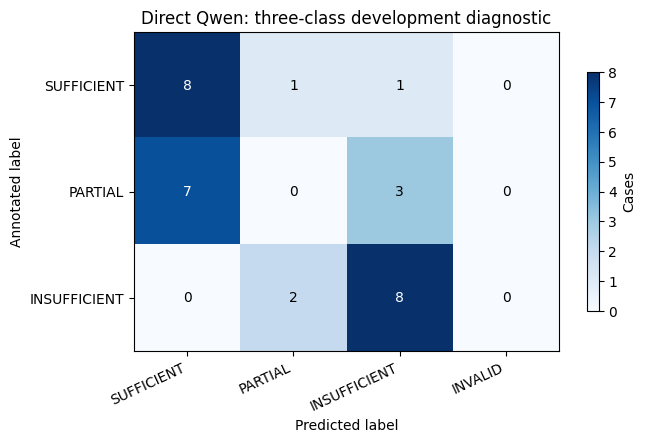

In [9]:
def plot_confusion(table, title):
    fig, ax = plt.subplots(figsize=(7, 4.4))
    im = ax.imshow(table.to_numpy(), cmap='Blues')
    ax.set_xticks(range(len(table.columns)), labels=table.columns, rotation=25, ha='right')
    ax.set_yticks(range(len(table.index)), labels=table.index)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Annotated label')
    ax.set_title(title)
    for (i, j), value in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, str(value), ha='center', va='center',
                color='white' if value > table.to_numpy().max()/2 else 'black')
    fig.colorbar(im, ax=ax, shrink=.75, label='Cases')
    fig.tight_layout()
    plt.show()

plot_confusion(cm_direct, 'Direct Qwen: three-class development diagnostic')

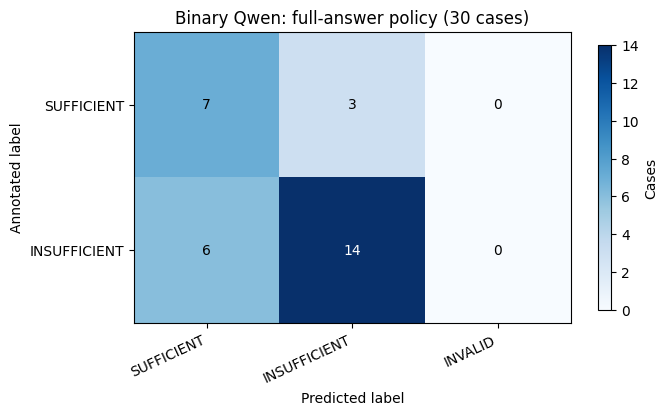

In [10]:
plot_confusion(cm_binary, 'Binary Qwen: full-answer policy (30 cases)')

### Error inspection: which queries actually changed?

For interpretation, we compare the old direct classifier mapped to the same binary accept/abstain decision against the new binary prompt. The two prompts only disagreed on **two** development cases: `suff_dev_010` (now an unnecessary rejection), and `suff_dev_020` (now a correct rejection of a partially supported question).

In [11]:
paired = (direct_rows[['case','gold_original','origin','predicted','accept']]
          .rename(columns={'predicted':'direct_status','accept':'direct_accept'})
          .merge(binary_rows[['case','predicted','accept','latency_s']], on='case', how='inner')
          .rename(columns={'predicted':'binary_status','accept':'binary_accept','latency_s':'binary_latency_s'}))
paired['correct_binary'] = paired['binary_accept'].eq(paired['gold_original'].eq('SUFFICIENT'))
display(paired.loc[paired['direct_accept'].ne(paired['binary_accept'])])
display(paired.loc[~paired['correct_binary'], ['case','gold_original','origin','direct_status','binary_status']])

,case,gold_original,origin,direct_status,direct_accept,binary_status,binary_accept,binary_latency_s,correct_binary
9,suff_dev_010,SUFFICIENT,saved_dev_retrieval,SUFFICIENT,True,INSUFFICIENT,False,15.997,False
19,suff_dev_020,PARTIAL,controlled,SUFFICIENT,True,INSUFFICIENT,False,9.034,True


,case,gold_original,origin,direct_status,binary_status
3,suff_dev_004,SUFFICIENT,saved_dev_retrieval,INSUFFICIENT,INSUFFICIENT
6,suff_dev_007,SUFFICIENT,saved_dev_retrieval,PARTIAL,INSUFFICIENT
9,suff_dev_010,SUFFICIENT,saved_dev_retrieval,SUFFICIENT,INSUFFICIENT
12,suff_dev_013,PARTIAL,controlled,SUFFICIENT,SUFFICIENT
13,suff_dev_014,PARTIAL,controlled,SUFFICIENT,SUFFICIENT
14,suff_dev_015,PARTIAL,controlled,SUFFICIENT,SUFFICIENT
15,suff_dev_016,PARTIAL,controlled,SUFFICIENT,SUFFICIENT
16,suff_dev_017,PARTIAL,controlled,SUFFICIENT,SUFFICIENT
17,suff_dev_018,PARTIAL,controlled,SUFFICIENT,SUFFICIENT


## 5. Counterfactual evidence test

The **question stays fixed** while we replace the evidence set; each group has equal chunk *count* across `S`, `P`, `I` but different content lengths. For the binary full-answer gate the ideal sequence is:

```text
Sufficient context → SUFFICIENT
Partial context  → INSUFFICIENT
No supported facts → INSUFFICIENT
```

A prediction change can suggest context sensitivity, but it does **not** establish faithful reasoning. Conversely, the same prediction across variants is a strong diagnostic when labels genuinely differ.

In [12]:
old_cf = pd.DataFrame([{
    'group': r['group_id'], 'variant': r['variant_id'],
    'gold': r['gold_status'], 'pred': extract_status(r['assessment'])
} for r in results['counterfactual_direct']['cases']])
new_cf = pd.DataFrame([{
    'group': r['group_id'], 'variant': r['variant_id'],
    'gold': r['gold_original'], 'pred': extract_status(r['assessment'])
} for r in results['counterfactual_binary']['cases']])
assert len(old_cf) == len(new_cf) == 12
joined = old_cf.rename(columns={'pred':'direct_3way'}).merge(
    new_cf.rename(columns={'pred':'binary'}).drop(columns='gold'), on=['group','variant'])
joined['old_binary_decision'] = np.where(joined['direct_3way'].eq('SUFFICIENT'), 'SUFFICIENT','INSUFFICIENT')
joined['expected_binary'] = joined['gold'].map(binary_gold)
joined['binary_correct'] = joined['binary'].eq(joined['expected_binary'])
assert joined['old_binary_decision'].eq(joined['binary']).all()
display(joined.sort_values(['group','variant']).loc[:,
    ['group','variant','gold','expected_binary','direct_3way','binary','binary_correct']])

,group,variant,gold,expected_binary,direct_3way,binary,binary_correct
2,cf_001,I,INSUFFICIENT,INSUFFICIENT,PARTIAL,INSUFFICIENT,True
1,cf_001,P,PARTIAL,INSUFFICIENT,SUFFICIENT,SUFFICIENT,False
0,cf_001,S,SUFFICIENT,SUFFICIENT,SUFFICIENT,SUFFICIENT,True
5,cf_002,I,INSUFFICIENT,INSUFFICIENT,INSUFFICIENT,INSUFFICIENT,True
4,cf_002,P,PARTIAL,INSUFFICIENT,SUFFICIENT,SUFFICIENT,False
3,cf_002,S,SUFFICIENT,SUFFICIENT,SUFFICIENT,SUFFICIENT,True
8,cf_003,I,INSUFFICIENT,INSUFFICIENT,INSUFFICIENT,INSUFFICIENT,True
7,cf_003,P,PARTIAL,INSUFFICIENT,INSUFFICIENT,INSUFFICIENT,True
6,cf_003,S,SUFFICIENT,SUFFICIENT,INSUFFICIENT,INSUFFICIENT,False
11,cf_004,I,INSUFFICIENT,INSUFFICIENT,SUFFICIENT,SUFFICIENT,False


In [13]:
triplets = []
for group, rows in joined.groupby('group'):
    lookup = rows.set_index('variant')
    sequence = tuple(lookup.loc[v, 'binary'] for v in ('S','P','I'))
    triplets.append({
        'group':group, 'question':by_id[cf_dataset['groups'][len(triplets)]['source_case_id']]['query'],
        'S':sequence[0], 'P':sequence[1], 'I':sequence[2],
        'exact_full_answer_policy':sequence==('SUFFICIENT','INSUFFICIENT','INSUFFICIENT')})
triplet_df = pd.DataFrame(triplets)
display(triplet_df)
print('Fully correct counterfactual triplets:', int(triplet_df.exact_full_answer_policy.sum()), '/', len(triplet_df))
print('Binary incorrect accepts among 8 negative variants:',
      int(((joined.expected_binary == 'INSUFFICIENT') & (joined.binary == 'SUFFICIENT')).sum()), '/ 8')

,group,question,S,P,I,exact_full_answer_policy
0,cf_001,"Según la información disponible, ¿qué síntomas...",SUFFICIENT,SUFFICIENT,INSUFFICIENT,False
1,cf_002,¿Qué mide un hemograma y para qué se utiliza?,SUFFICIENT,SUFFICIENT,INSUFFICIENT,False
2,cf_003,"En Demo Health Clinic, ¿con cuánto aviso se ca...",INSUFFICIENT,INSUFFICIENT,INSUFFICIENT,False
3,cf_004,"¿Qué puede causar diarrea, qué señales justifi...",SUFFICIENT,SUFFICIENT,SUFFICIENT,False


Fully correct counterfactual triplets: 0 / 4
Binary incorrect accepts among 8 negative variants: 4 / 8


**Counterfactual finding:** the direct→binary and new binary gate made **identical accept/abstain decisions in all 12 cases**. Each gave **7/12 correct**, **4/8 false acceptances** of not-fully-supported contexts, and **0/4 entirely correct triplets**. Three partial variants were incorrectly allowed; one fully unsupported variant was allowed. Binary wording alone did not fix requirement coverage.

## 6. Early exploratory alternatives (six repeatedly inspected cases)

The paired pilot compared direct classification with **requirements decomposition**. The latter frequently produced malformed/internally inconsistent outputs and sometimes associated irrelevant evidence with a supposed requirement. Post-hoc deterministic aggregation can fix logical inconsistency but cannot repair unsupported semantic claims. A separate mandatory-literal-quote pilot increased runtime and format failures: finding a literal passage substring is **not** equivalent to evidence support.

The archived quote/aggregation scripts and raw JSON outputs were intentionally removed from the main repository as redundant experiments. Their aggregate findings remain documented here; the six-case pilot is retained as a compact historical record. These tiny **prompt-development** cases must not be treated as a model-selection holdout.

In [14]:
pilot_rows=[]
for case in results['pilot']['cases']:
    for method, output in case['conditions'].items():
        pilot_rows.append({
            'case':case['case_id'], 'gold':case['gold_status'], 'method':method,
            'valid_structure':output['valid_structure'],
            'predicted':extract_status(output),
            'exact_global':output['valid_structure'] and extract_status(output)==case['gold_status'],
            'latency_s':output['latency_seconds'],
        })
pilot_df = pd.DataFrame(pilot_rows)
display(pilot_df)
display(pilot_df.groupby('method', as_index=False).agg(
    cases=('case','count'), valid=('valid_structure','sum'),
    correct_global=('exact_global','sum'), mean_cpu_seconds=('latency_s','mean')).round(2))

,case,gold,method,valid_structure,predicted,exact_global,latency_s
0,suff_dev_001,SUFFICIENT,direct,True,SUFFICIENT,True,10.242
1,suff_dev_001,SUFFICIENT,decomposed,False,INVALID,False,24.678
2,suff_dev_009,SUFFICIENT,decomposed,False,INVALID,False,34.800
3,suff_dev_009,SUFFICIENT,direct,True,SUFFICIENT,True,11.628
4,suff_dev_011,PARTIAL,direct,True,INSUFFICIENT,False,6.907
5,suff_dev_011,PARTIAL,decomposed,True,PARTIAL,True,33.030
6,suff_dev_013,PARTIAL,decomposed,True,PARTIAL,True,30.830
7,suff_dev_013,PARTIAL,direct,True,SUFFICIENT,False,6.775
8,suff_dev_025,INSUFFICIENT,direct,True,INSUFFICIENT,True,12.179
9,suff_dev_025,INSUFFICIENT,decomposed,False,INVALID,False,33.690


,method,cases,valid,correct_global,mean_cpu_seconds
0,decomposed,6,3,3,29.37
1,direct,6,6,4,9.05


## 7. Runtime and implementation

The model is evaluated **in a separate inference before generation** when the optional gate is on. In development, this adds roughly 8–18 seconds per assessment on the measured CPU; this is not an API latency benchmark. Empty contexts follow the deterministic retriever fallback and must be excluded from LLM latency and semantic performance estimates.

**Production boundary:** `app/chatbot/evidence.py` owns the binary prompt, output validation and gate. The `MedicalAssistance` service chooses whether to assess after retrieval. Invalid gate output fails closed; runtime inference errors remain service errors. The source list indicates retrieved provenance, **not** claim-level proof.

In [15]:
latency = pd.DataFrame([
    {'method':'Direct three-way','n_model_calls':int(direct_rows.invoked.sum()),
     'mean_seconds':direct_rows.loc[direct_rows.invoked,'latency_s'].mean(),
     'median_seconds':direct_rows.loc[direct_rows.invoked,'latency_s'].median()},
    {'method':'Binary full-answer','n_model_calls':int(binary_rows.invoked.sum()),
     'mean_seconds':binary_rows.loc[binary_rows.invoked,'latency_s'].mean(),
     'median_seconds':binary_rows.loc[binary_rows.invoked,'latency_s'].median()},
])
display(latency.round(2))

,method,n_model_calls,mean_seconds,median_seconds
0,Direct three-way,28,11.14,10.50
1,Binary full-answer,28,13.29,12.38


### Compare the same generator model in both branches

```bash
# Baseline behavior of the *same* 1.5B model, greedy
MEDICAL_EVIDENCE_GATE_ENABLED=0 MEDICAL_LLM_MODEL=Qwen/Qwen2.5-1.5B-Instruct MEDICAL_LLM_DO_SAMPLE=0 \
  uvicorn app.main:app --host 127.0.0.1 --port 8000

# Experimental binary gate enabled
MEDICAL_EVIDENCE_GATE_ENABLED=1 MEDICAL_LLM_MODEL=Qwen/Qwen2.5-1.5B-Instruct MEDICAL_LLM_DO_SAMPLE=0 \
  uvicorn app.main:app --host 127.0.0.1 --port 8000
```

The disabled-by-default production configuration can use a smaller generator; it is **not** an appropriate controlled comparator for gate effectiveness unless the model configuration is held fixed.

## 8. Optional: regenerate **binary** model decisions

This cell is **off by default** and is never required for analysis. If enabled, it loads Qwen2.5-1.5B on CPU, takes exactly the *saved* question and evidence chunk IDs (no live retriever call), and calls the **production** binary gate prompt/parser. It writes a **new, versioned replication artifact** rather than overwriting the frozen results, since deleting historical runners necessarily changes their source-code fingerprints.

**Prerequisites:** app model dependencies and `evaluation/datasets/chunk_catalog.json`. Runtime can be substantial. Controlled contexts are deliberately passed directly to the gate without retrieval; this is not a new retrieval evaluation.

In [16]:
RUN_BINARY_REPLICATION = False  # Explicit opt-in: this loads Qwen and runs inference.
REPLICATION_STUDY = 'dev'  # 'dev' or 'counterfactual'

if RUN_BINARY_REPLICATION:
    import time
    from datetime import datetime, timezone
    from app.chatbot.evidence import BinaryEvidenceGate
    from app.chatbot.llm import QwenLLM
    from app.chatbot.models import Chunk, RetrievedChunk

    catalog_path = EVAL / 'datasets' / 'chunk_catalog.json'
    catalog = {c['chunk_id']: c for c in read_json(catalog_path)}
    llm = QwenLLM(model_name='Qwen/Qwen2.5-1.5B-Instruct', do_sample=False)
    gate = BinaryEvidenceGate(llm)
    entries = []
    if REPLICATION_STUDY == 'dev':
        source_rows = [(c['case_id'], c['query'], c['evidence_chunk_ids'], c['expected_sufficiency'])
                       for c in dataset['cases']]
    elif REPLICATION_STUDY == 'counterfactual':
        source_rows = [(f"{g['group_id']}:{v['variant_id']}", by_id[g['source_case_id']]['query'],
                        v['evidence_chunk_ids'], v['expected_sufficiency'])
                       for g in cf_dataset['groups'] for v in g['variants']]
    else:
        raise ValueError('REPLICATION_STUDY must be dev or counterfactual')

    for key, query, ids, gold in source_rows:
        chunks = [RetrievedChunk(chunk=Chunk(**{
            k: catalog[chunk_id][k] for k in
            ('chunk_id','document_id','title','source','source_url','section','content')
        }), score=0.0) for chunk_id in ids]
        start = time.perf_counter()
        if not chunks:
            status, origin = 'INSUFFICIENT', 'deterministic_no_context'
        else:
            try:
                status, origin = gate.assess(query, chunks), 'model'
            except Exception as exc:
                status, origin = 'ERROR', type(exc).__name__
        entries.append({'case':key,'gold_original':gold,'predicted':status,
                        'origin':origin,'latency_seconds':round(time.perf_counter()-start,3)})

    out = {
        'study':'notebook_binary_replication',
        'annotation_status':dataset['annotation_status'],
        'model_name':'Qwen/Qwen2.5-1.5B-Instruct',
        'model_config':{'do_sample':False,'max_new_tokens':256},
        'source_sha256':{'dataset':fingerprint(EVAL/'datasets'/'sufficiency_dev.json'),
                         'catalog':fingerprint(catalog_path)},
        'cases':entries,
    }
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    output_path = RES / f'replication_binary_{REPLICATION_STUDY}_{stamp}.json'
    output_path.write_text(json.dumps(out, ensure_ascii=False, indent=2), encoding='utf-8')
    print('Saved new replication:', output_path)

## 9. Engineering decision and remaining limitations

**Selected architecture:** keep the original RAG pipeline; expose the binary sufficiency assessment as an **experimental opt-in switch**, off by default. The gate shares the local Qwen instance with the generator when enabled. Do not present 1.5B prompt experiments as proof that the original 0.5B generator is safe or that the integrated system answers accurately.

**Why no mandatory gate yet?** The gate rejects several obvious unsupported requests that passed similarity thresholding, but fails on partially supported compound questions (6/10 accepted in the development set). It also incurs extra latency and sometimes refuses fully supported questions. Repeated prompt tuning on these development examples risks overfitting.

**Threats to validity:** small curated and balanced diagnostics; non-independent contexts; 6 frequently inspected cases; all partial examples controlled; gold annotations awaiting author sign-off; incomplete passage-length control; exact source hashes refer to frozen historical files; correct gate decisions do not guarantee the downstream generated claims are supported. Fictional clinic policy facts must not be interpreted as real guidance.

**Next experiment (separate project stage):** a new, author-reviewed end-to-end evaluation, with both branches using **identical** Qwen model settings and retrieval results, measuring unsupported factual claims, response completeness, abstention behavior, source provenance and latency. The retrieval test split must not be repurposed as a gate-tuning set.

---

**Companion stage:** [`retrieval_analysis.ipynb`](retrieval_analysis.ipynb). That notebook asks *which evidence was retrieved*; this notebook asks *whether the retrieved evidence can answer the full question*.